# Mini Batch GD

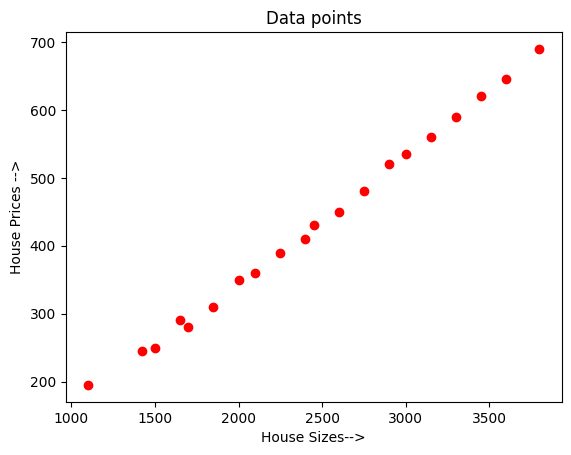

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import random

# House sizes in square feet (will be divided by 1000 in your code -> 1.1 to 3.8)
house_size = [
    1100, 1420, 1500, 1650, 1700, 1850, 2000, 2100, 2250, 2400,
    2450, 2600, 2750, 2900, 3000, 3150, 3300, 3450, 3600, 3800
]

# House prices (in thousands) matching the sizes with a bit of noise
house_price = [
    195, 245, 250, 290, 280, 310, 350, 360, 390, 410,
    430, 450, 480, 520, 535, 560, 590, 620, 645, 690
]

plt.scatter(house_size, house_price, marker='o', color = 'Red')
plt.xlabel('House Sizes-->')
plt.ylabel('House Prices -->')
plt.title('Data points')
plt.show()

Total epoch: 1, Knobs: [0.0028875 0.004991 ], height 0.09568438581418391
Total epoch: 2, Knobs: [0.00818078 0.02180466], height 0.07578930420198443
Total epoch: 3, Knobs: [0.01138562 0.02974941], height 0.06695345064012619
Total epoch: 4, Knobs: [0.01529115 0.04145717], height 0.05519109037617414
Total epoch: 5, Knobs: [0.01893476 0.05232971], height 0.0452849723080727
Total epoch: 6, Knobs: [0.02216884 0.06190111], height 0.03737284332512949
Total epoch: 7, Knobs: [0.02436926 0.0672998 ], height 0.03315673137845491
Total epoch: 8, Knobs: [0.02653295 0.07266454], height 0.029224669363725694
Total epoch: 9, Knobs: [0.0293331 0.0813791], height 0.02351584447598659
Total epoch: 10, Knobs: [0.03100407 0.08511595], height 0.02117021814539841
Total epoch: 11, Knobs: [0.03283689 0.09028434], height 0.01821653205441634
Total epoch: 12, Knobs: [0.03484706 0.09604278], height 0.015196331522444862
Total epoch: 13, Knobs: [0.03674441 0.10169518], height 0.01251392783025695
Total epoch: 14, Knobs: 

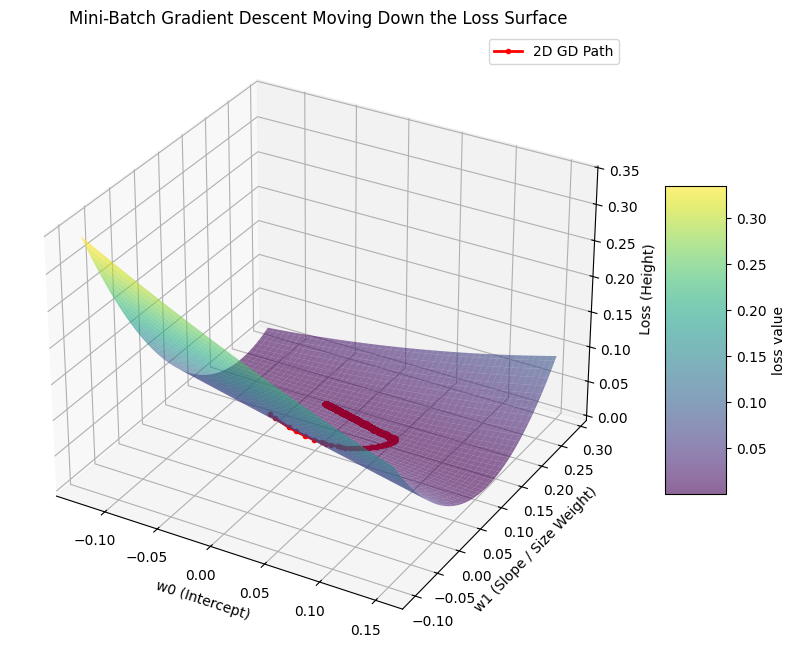

[]

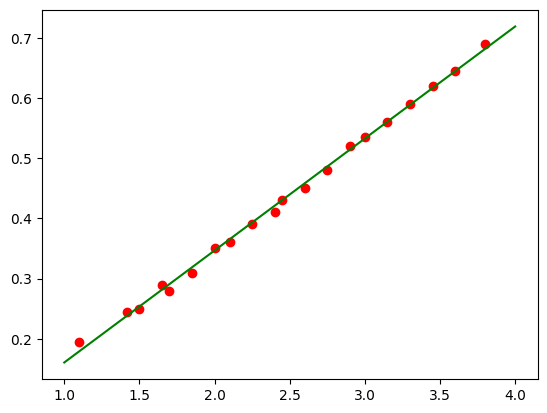

In [21]:
x = [i/1000 for i in house_size] #house size
y = [i/1000 for i in house_price]

tol = 1e-6
max_iter = 10000
k = 0
alpha = 0.01
length = len(x)
w= np.array([0,0])
history_of_w0 = [w[0]]
history_of_w1 = [w[1]]


def l(w0,w1,length):
    summation_of_error = 0
    for i in range(length):
        error = y[i] - (w0 + w1 * x[i])
        summation_of_error = summation_of_error + (error**2)
    Z = (1/(2*length)) * summation_of_error
    return Z


history_of_Z = [l(w[0], w[1], length= length)]


def mini_batch_gradient(w0, w1, batch_size = 4):

    #combine them to get a combine list
    combined_list = list(zip(x,y))
    #get a random value pair
    random_sample = random.sample(combined_list, k= batch_size)

    #separate them back into independent lists:
    batch_x,batch_y = zip(*random_sample) # this uses unpacking operator (*) to split the paired samples right back into two separate clean tupple
    
    summation_of_error_w0 = 0
    summation_of_error_w1 = 0

    for i in range(batch_size):
        error = batch_y[i] - (w0 + w1*batch_x[i])

        summation_of_error_w0 = summation_of_error_w0 + error
        summation_of_error_w1 = summation_of_error_w1 + (error*batch_x[i])

    partial_derivative_of_w0 = -1/batch_size * summation_of_error_w0
    partial_derivative_of_w1 = -1/batch_size * summation_of_error_w1

    return np.array([partial_derivative_of_w0, partial_derivative_of_w1])



while np.linalg.norm(mini_batch_gradient(w[0],w[1],batch_size=4))>tol and max_iter>k:

    #direction = 
    direction = -mini_batch_gradient(w0=w[0], w1=w[1], batch_size=4)

    new_pos = w + (alpha * direction)

    #update
    w = new_pos

    history_of_w0.append(w[0])
    history_of_w1.append(w[1])
    history_of_Z.append(l(w0=w[0], w1=w[1], length=length))

    k +=1

    print(f'Total epoch: {k}, Knobs: {w}, height {l(w[0], w[1], length=length)}')


#plotting the gradient decent:
fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(projection='3d')

X_surf = np.linspace(min(history_of_w0)-0.1, max(history_of_w0)+0.1, 100)
Y_surf = np.linspace(min(history_of_w1)-0.1, max(history_of_w1)+0.1, 100)
X,Y = np.meshgrid(X_surf, Y_surf)
Z = l(X,Y, length= length)

surf = ax.plot_surface(X,Y,Z,cmap='viridis', alpha=0.6) #the 3d land
fig.colorbar(surf, ax=ax, shrink= 0.5, aspect=5, label='loss value')

ax.plot(history_of_w0, history_of_w1, history_of_Z, color = 'Red', marker='.', linewidth = 2,label='2D GD Path')

ax.set_xlabel('w0 (Intercept)')
ax.set_ylabel('w1 (Slope / Size Weight)')
ax.set_zlabel('Loss (Height)')
ax.set_title('Mini-Batch Gradient Descent Moving Down the Loss Surface')
ax.legend()
plt.show()



#plotting the line:
plt.scatter(x,y, color='Red', marker='o')

X = np.linspace(1,4,100)
Y = w[0] + w[1] * X
plt.plot(X,Y, color='Green')
plt.plot()